# Phân tích hành vi khách hàng thương mại điện tử — IE313

**Mục tiêu:** phân tích tổng quan khách hàng, chi tiêu, hành vi mua và mức hài lòng trên cùng dữ liệu sạch và cùng bộ lọc.

**Nguồn:** `data/E-commerce_Customer_Behavior.csv`; mỗi dòng được kiểm tra như một khách qua `Customer ID`.

**Phạm vi:** thống kê mô tả, so sánh nhóm và Pearson. Không có mô hình dự đoán, doanh thu theo thời gian, phễu chuyển đổi hoặc RFM đầy đủ.

**Đơn vị `Total Spend`:** chưa xác định vì CSV không xác nhận USD/VND.

## 1. Import và nạp dữ liệu

**Kỹ thuật:** dùng đường dẫn tương đối và `load_clean_data()` trong `analysis_core.py`. Dashboard và notebook cùng gọi logic này để tránh lệch số liệu.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from analysis_core import (
    MEMBERSHIPS, SATISFACTION_LEVELS, SEGMENT_ORDER, SPEND_AXIS_LABEL, SPEND_UNIT,
    apply_filters, assign_customer_segments, city_behavior_profile, compute_kpis,
    fixed_segmentation_thresholds, load_clean_data,
)
DATA_PATH = Path("data/E-commerce_Customer_Behavior.csv")
CHARTS_PATH = Path("charts"); CHARTS_PATH.mkdir(exist_ok=True)
raw = pd.read_csv(DATA_PATH)
df, audit = load_clean_data(DATA_PATH)
print(f"Gốc: {raw.shape}; sau làm sạch: {df.shape}")
print(df.head().to_string(index=False))
print(); df.info()


Gốc: (350, 11); sau làm sạch: (350, 11)
 Customer ID Gender  Age          City Membership Type  Total Spend  Items Purchased  Average Rating  Discount Applied  Days Since Last Purchase Satisfaction Level
         101 Female   29      New York            Gold      1120.20               14             4.6              True                        25          Satisfied
         102   Male   34   Los Angeles          Silver       780.50               11             4.1             False                        18            Neutral
         103 Female   43       Chicago          Bronze       510.75                9             3.4              True                        42        Unsatisfied
         104   Male   30 San Francisco            Gold      1480.30               19             4.7             False                        12          Satisfied
         105   Male   27         Miami          Silver       720.40               13             4.0              True                      

## 2. Kiểm tra chất lượng

**Kỹ thuật:** kiểm tra cột, kiểu dữ liệu, thiếu, dòng trùng, ID trùng, lỗi chuyển kiểu và miền giá trị. Không thay dữ liệu lỗi bằng 0.

In [2]:
quality = pd.DataFrame({"Kiểu gốc": raw.dtypes.astype(str), "Thiếu": raw.isna().sum(), "Thiếu (%)": (raw.isna().mean()*100).round(2)})
print(quality.to_string())
print(); print(f"Dòng trùng hoàn toàn: {audit['exact_duplicates']}")
print(f"ID trùng sau làm sạch: {audit['duplicate_customer_ids']}")
print("Giá trị không hợp lệ theo quy tắc:"); print(pd.Series(audit['invalid_by_rule']).to_string())

                         Kiểu gốc  Thiếu  Thiếu (%)
Customer ID                 int64      0       0.00
Gender                     object      0       0.00
Age                         int64      0       0.00
City                       object      0       0.00
Membership Type            object      0       0.00
Total Spend               float64      0       0.00
Items Purchased             int64      0       0.00
Average Rating            float64      0       0.00
Discount Applied             bool      0       0.00
Days Since Last Purchase    int64      0       0.00
Satisfaction Level         object      2       0.57

Dòng trùng hoàn toàn: 0
ID trùng sau làm sạch: 0
Giá trị không hợp lệ theo quy tắc:
Age                         0
Total Spend                 0
Items Purchased             0
Average Rating              0
Discount Applied            0
Days Since Last Purchase    0
Gender                      0
City                        0
Membership Type             0
Customer ID          

## 3. Làm sạch và đối chiếu

- Chuẩn hóa chuỗi, numeric và Boolean; không âm thầm ép lỗi thành 0.
- Loại dòng trùng hoàn toàn và dòng lõi không hợp lệ; nếu ID còn trùng thì dừng để xác định quy tắc gộp.
- Kiểm tra `Average Rating` trong thang 1–5.
- Giữ 2 dòng thiếu `Satisfaction Level`; chỉ loại khỏi CH08.

In [3]:
comparison = pd.DataFrame({
 "Chỉ tiêu": ["Số dòng", "Số cột", "Dòng trùng", "Dòng lõi không hợp lệ đã loại", "ID duy nhất", "Thiếu hài lòng"],
 "Trước": [len(raw), raw.shape[1], audit['exact_duplicates'], 0, raw['Customer ID'].nunique(), raw['Satisfaction Level'].isna().sum()],
 "Sau": [len(df), df.shape[1], 0, audit['invalid_core_rows_removed'], df['Customer ID'].nunique(), df['Satisfaction Level'].isna().sum()]})
print(comparison.to_string(index=False))
print(f"Average Rating quan sát: {df['Average Rating'].min():.1f}–{df['Average Rating'].max():.1f}; kiểm tra trong thang 1–5.")

                     Chỉ tiêu  Trước  Sau
                      Số dòng    350  350
                       Số cột     11   11
                   Dòng trùng      0    0
Dòng lõi không hợp lệ đã loại      0    0
                  ID duy nhất    350  350
               Thiếu hài lòng      2    2
Average Rating quan sát: 3.0–4.9; kiểm tra trong thang 1–5.


## 4. Thống kê mô tả

**Kỹ thuật:** tính count, mean, median, Q1, Q3, IQR và độ lệch chuẩn. `Customer ID` chỉ dùng để đếm khách.

In [4]:
summary_cols=["Age","Total Spend","Items Purchased","Average Rating","Days Since Last Purchase"]
summary=df[summary_cols].describe().T[["count","mean","std","min","25%","50%","75%","max"]]
summary["IQR"]=summary["75%"]-summary["25%"]
print(summary.round(2).to_string())
q1,q3=df["Total Spend"].quantile([.25,.75]); iqr=q3-q1; lower=q1-1.5*iqr; upper=q3+1.5*iqr
print(f"Ngưỡng boxplot: [{lower:.2f}, {upper:.2f}]; ngoại lệ: {((df['Total Spend']<lower)|(df['Total Spend']>upper)).sum()}; không tự động xóa.")

                          count    mean     std    min    25%    50%     75%     max    IQR
Age                       350.0   33.60    4.87   26.0   30.0   32.5    37.0    43.0    7.0
Total Spend               350.0  845.38  362.06  410.8  502.0  775.2  1160.6  1520.1  658.6
Items Purchased           350.0   12.60    4.16    7.0    9.0   12.0    15.0    21.0    6.0
Average Rating            350.0    4.02    0.58    3.0    3.5    4.1     4.5     4.9    1.0
Days Since Last Purchase  350.0   26.59   13.44    9.0   15.0   23.0    38.0    63.0   23.0
Ngưỡng boxplot: [-485.90, 2148.50]; ngoại lệ: 0; không tự động xóa.


## 5. Bộ lọc chung và KPI

`None` nghĩa là chọn **Tất cả**. KPI01–KPI06 và CH01–CH10 đều dùng `analysis_df`, giống bộ lọc chung của dashboard.

In [5]:
FILTERS={"cities":None,"genders":None,"memberships":None,"discounts":None,"age_range":None,"satisfaction":None}
analysis_df=apply_filters(df,**FILTERS); kpis=compute_kpis(analysis_df)
kpi_table=pd.DataFrame({
 "KPI":["KPI01 Số khách","KPI02 Tổng chi tiêu ghi nhận","KPI03 Chi tiêu trung vị/khách","KPI04 Điểm đánh giá TB","KPI05 Tỷ lệ có giảm giá","KPI06 Trung vị ngày chưa mua"],
 "Giá trị":[kpis['customers'],kpis['total_spend'],kpis['median_spend'],kpis['mean_rating'],kpis['discount_rate'],kpis['median_days']],
 "Đơn vị/mẫu số":["ID duy nhất",SPEND_UNIT,SPEND_UNIT,f"n={kpis['rating_n']}",f"%, mẫu số={kpis['discount_n']}","ngày"]})
print(f"N = {analysis_df['Customer ID'].nunique()} khách"); print(kpi_table.to_string(index=False))

N = 350 khách
                          KPI       Giá trị        Đơn vị/mẫu số
               KPI01 Số khách    350.000000          ID duy nhất
 KPI02 Tổng chi tiêu ghi nhận 295883.600000 đơn vị chưa xác định
KPI03 Chi tiêu trung vị/khách    775.200000 đơn vị chưa xác định
       KPI04 Điểm đánh giá TB      4.019143                n=350
      KPI05 Tỷ lệ có giảm giá     50.000000        %, mẫu số=350
 KPI06 Trung vị ngày chưa mua     23.000000                 ngày


## 6. Thiết lập biểu đồ

Biểu đồ dùng màu nhất quán, có tiêu đề/trục/đơn vị, xuất vào `charts/`; cột có khoảng cách để dễ đọc.

In [6]:
plt.rcParams.update({"figure.figsize":(10,5.5),"figure.dpi":110,"font.family":"DejaVu Sans","axes.titlesize":15,"axes.spines.top":False,"axes.spines.right":False})
COLORS={"Bronze":"#36B9B5","Silver":"#678CF0","Gold":"#E9AD51"}; SAT_COLORS={"Unsatisfied":"#E98294","Neutral":"#678CF0","Satisfied":"#36B9B5"}
SEGMENT_COLORS={
    "Chi tiêu cao · mua gần đây":"#0F8C86",
    "Chi tiêu cao · mua đã lâu":"#E98294",
    "Chi tiêu thấp · mua gần đây":"#678CF0",
    "Chi tiêu thấp · mua đã lâu":"#9AA5B5",
}
def tidy(ax): ax.grid(axis="y",alpha=.25); ax.set_axisbelow(True); return ax
def save_chart(fig,name): fig.savefig(CHARTS_PATH/name,dpi=160,bbox_inches="tight",facecolor="white")
print("Đã thiết lập giao diện và charts/.")


Đã thiết lập giao diện và charts/.


## 7. Nhóm A — Tổng quan

### CH01 — Histogram độ tuổi

**Kỹ thuật:** histogram khoảng 5 tuổi.

**Ghi chú dữ liệu:** dùng `Age` từ `analysis_df`; điều kiện là bộ lọc chung. Tiêu chí: tổng số đếm bằng N khách có tuổi hợp lệ.

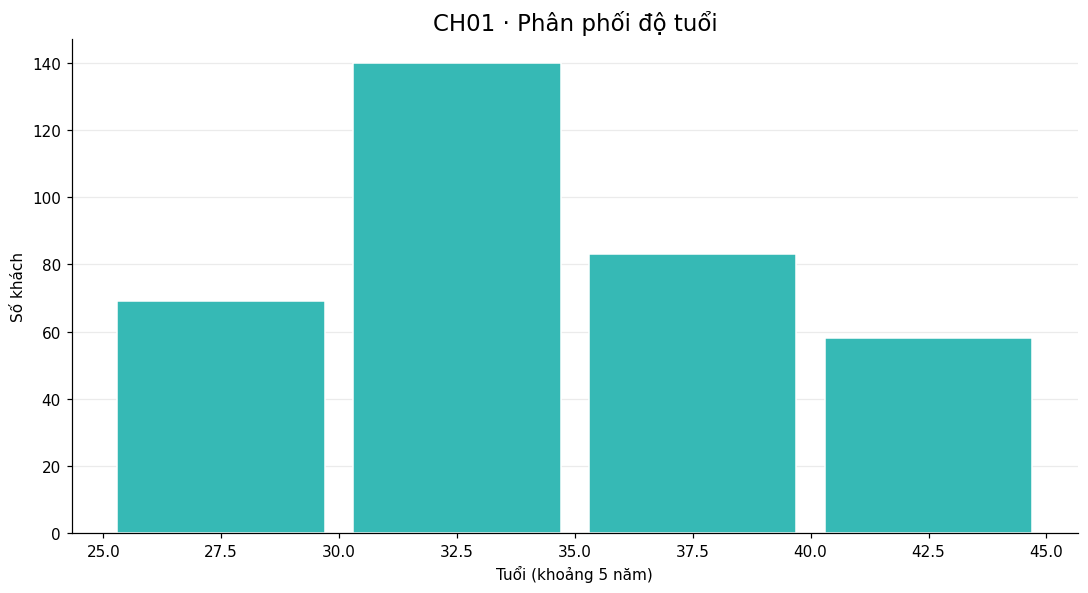

Tổng đếm=350; N hợp lệ=350; mode=30.


In [7]:
age=analysis_df["Age"].dropna(); start=int(age.min())//5*5; bins=np.arange(start,int(age.max())+6,5)
fig,ax=plt.subplots(); counts,_,_=ax.hist(age,bins=bins,color="#36B9B5",edgecolor="white",rwidth=.88)
ax.set(title="CH01 · Phân phối độ tuổi",xlabel="Tuổi (khoảng 5 năm)",ylabel="Số khách")
tidy(ax); plt.tight_layout(); save_chart(fig,"CH01_histogram_do_tuoi.png"); plt.show()
print(f"Tổng đếm={int(counts.sum())}; N hợp lệ={len(age)}; mode={age.mode().iloc[0]}.")

**Nhận xét:** 350 khách có tuổi 26–43; tuổi 30 xuất hiện nhiều nhất với 48 khách. Khoảng 5 năm chỉ phục vụ trực quan hóa.

### CH02 — Số khách theo thành phố

**Kỹ thuật:** đếm `Customer ID` duy nhất theo `City` và sắp xếp giảm dần.

**Ghi chú dữ liệu:** dùng `City`, `Customer ID`; mỗi cột là số khách, không phải tổng chi tiêu. Tiêu chí: tổng cột bằng N.

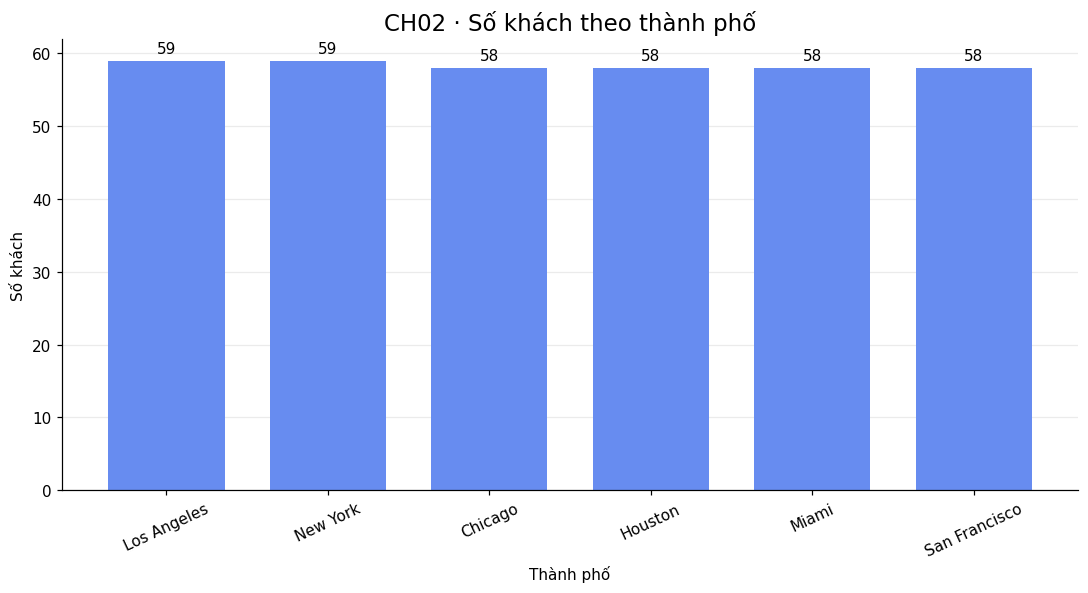

City
Los Angeles      59
New York         59
Chicago          58
Houston          58
Miami            58
San Francisco    58
Tổng=350; N=350.


In [8]:
city_counts=analysis_df.groupby("City")["Customer ID"].nunique().sort_values(ascending=False)
fig,ax=plt.subplots(); bars=ax.bar(city_counts.index,city_counts.values,width=.72,color="#678CF0"); ax.bar_label(bars,padding=3)
ax.set(title="CH02 · Số khách theo thành phố",xlabel="Thành phố",ylabel="Số khách"); ax.tick_params(axis="x",rotation=25)
tidy(ax); plt.tight_layout(); save_chart(fig,"CH02_so_khach_theo_thanh_pho.png"); plt.show()
print(city_counts.to_string()); print(f"Tổng={city_counts.sum()}; N={analysis_df['Customer ID'].nunique()}.")

**Nhận xét:** New York và Los Angeles cùng có 59 khách; bốn thành phố còn lại có 58 khách. Phân bố gần như cân bằng.

### CH03 — Cơ cấu hạng thành viên

**Kỹ thuật:** biểu đồ tròn dạng donut thể hiện tỷ trọng khách hàng của từng hạng; nhãn trên lát cắt cho biết tỷ lệ và số khách.

**Ghi chú dữ liệu:** dùng `Membership Type`, `Customer ID`; phạm vi Bronze/Silver/Gold. Chỉ đếm `Customer ID` duy nhất trong tập dữ liệu sau bộ lọc. Tiêu chí kiểm tra: tổng số khách bằng N và tổng tỷ trọng bằng 100%.

**Cách đọc:** lát cắt lớn hơn biểu thị hạng có nhiều khách hàng hơn; màu Bronze/Silver/Gold được giữ nhất quán với các biểu đồ khác.


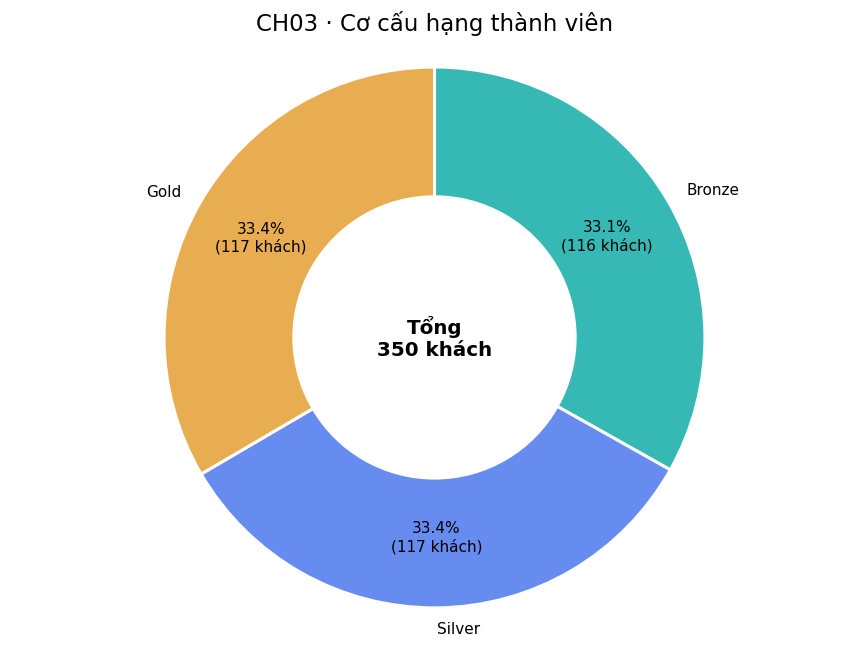

                 Số khách  Tỷ trọng (%)
Membership Type                        
Bronze                116          33.1
Silver                117          33.4
Gold                  117          33.4
Tổng số khách=350; tổng tỷ trọng=100.0%.


In [9]:
# Nguồn: Membership Type và Customer ID trong tập dữ liệu sau bộ lọc chung.
# Phạm vi: ba hạng Bronze, Silver và Gold; mỗi khách chỉ được đếm một lần.
membership_counts = (analysis_df.groupby("Membership Type")["Customer ID"]
                     .nunique().reindex(MEMBERSHIPS, fill_value=0))
membership_counts = membership_counts[membership_counts > 0]
membership_pct = membership_counts / membership_counts.sum() * 100
membership_total = int(membership_counts.sum())

fig, ax = plt.subplots(figsize=(8, 6))
wedges, labels, values = ax.pie(
    membership_counts.values,
    labels=membership_counts.index,
    colors=[COLORS[name] for name in membership_counts.index],
    startangle=90,
    counterclock=False,
    autopct=lambda pct: f"{pct:.1f}%\n({pct / 100 * membership_total:.0f} khách)",
    pctdistance=0.74,
    labeldistance=1.08,
    wedgeprops={"width": 0.48, "edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 10},
)
ax.text(0, 0, f"Tổng\n{membership_total} khách", ha="center", va="center", fontsize=13, fontweight="bold")
ax.set_title("CH03 · Cơ cấu hạng thành viên")
ax.axis("equal")
plt.tight_layout()
save_chart(fig, "CH03_co_cau_hang_thanh_vien.png")
plt.show()

# Kiểm tra: số khách theo hạng phải cộng thành N và tỷ trọng phải bằng 100%.
print(pd.DataFrame({"Số khách": membership_counts, "Tỷ trọng (%)": membership_pct.round(1)}).to_string())
print(f"Tổng số khách={membership_total}; tổng tỷ trọng={membership_pct.sum():.1f}%.")


**Nhận xét:** Bronze 116 khách (33,1%); Silver và Gold cùng 117 khách (33,4%). Mẫu gần như cân bằng.

## 8. Nhóm B — Chi tiêu và hành vi mua

### CH04 — Histogram tổng chi tiêu

**Kỹ thuật:** histogram kèm mean và median.

**Ghi chú dữ liệu:** dùng `Total Spend`; không xóa ngoại lệ chỉ vì ngoài boxplot. Đơn vị tiền tệ chưa xác định. Tiêu chí: số khách theo khoảng.

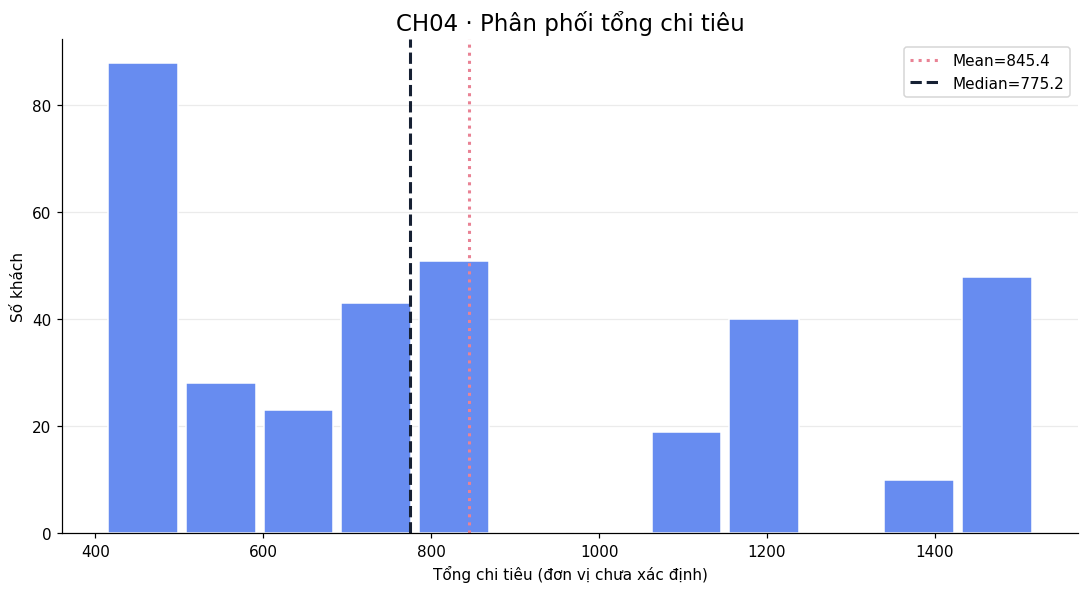

Mean=845.38; median=775.20; min–max=410.80–1520.10.


In [10]:
spend=analysis_df["Total Spend"].dropna(); fig,ax=plt.subplots(); ax.hist(spend,bins=12,color="#678CF0",edgecolor="white",rwidth=.9)
ax.axvline(spend.mean(),color="#E98294",linestyle=":",linewidth=2,label=f"Mean={spend.mean():,.1f}"); ax.axvline(spend.median(),color="#162033",linestyle="--",linewidth=2,label=f"Median={spend.median():,.1f}")
ax.set(title="CH04 · Phân phối tổng chi tiêu",xlabel=SPEND_AXIS_LABEL,ylabel="Số khách"); ax.legend(); tidy(ax); plt.tight_layout(); save_chart(fig,"CH04_histogram_tong_chi_tieu.png"); plt.show()
print(f"Mean={spend.mean():.2f}; median={spend.median():.2f}; min–max={spend.min():.2f}–{spend.max():.2f}.")

**Nhận xét:** mean 845,38 cao hơn median 775,20. CSV không xác nhận USD/VND nên không tự gán tiền tệ.

### CH05 — Boxplot chi tiêu theo hạng

**Kỹ thuật:** so sánh median, IQR, râu, ngoại lệ; nhãn ghi n từng hạng.

**Ghi chú dữ liệu:** dùng `Membership Type`, `Total Spend`, `Customer ID`; không loại ngoại lệ. Tiêu chí chính là median và IQR; không suy luận nhân quả.

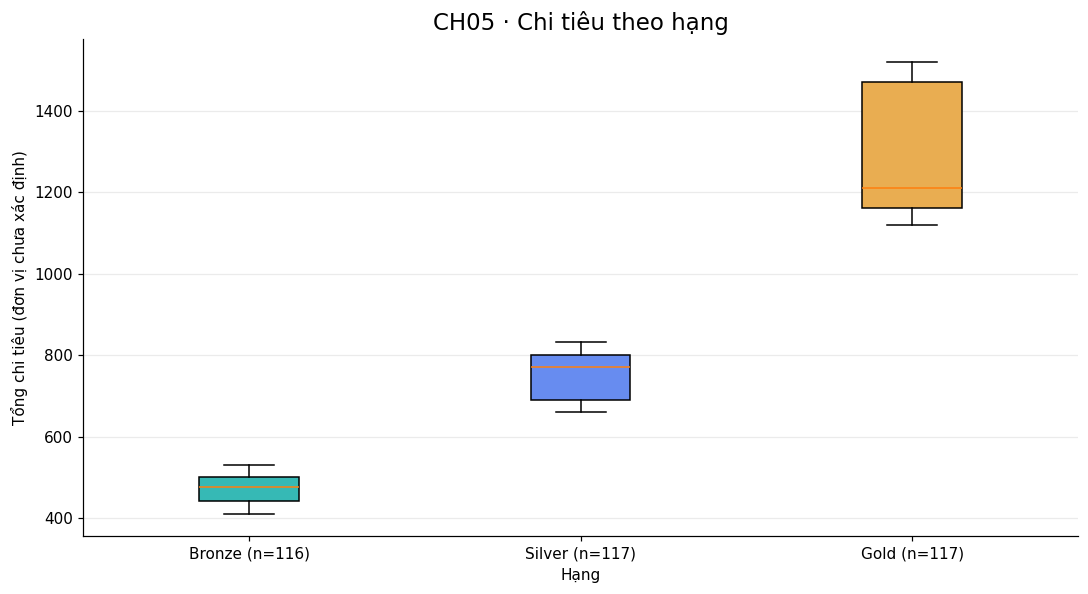

                 count     mean   median
Membership Type                         
Bronze             116   473.39   475.25
Gold               117  1311.14  1210.60
Silver             117   748.43   770.20


In [11]:
groups=[analysis_df.loc[analysis_df["Membership Type"]==m,"Total Spend"] for m in MEMBERSHIPS]; ns=[len(g) for g in groups]
fig,ax=plt.subplots(); bp=ax.boxplot(groups,patch_artist=True,tick_labels=[f"{m} (n={v})" for m,v in zip(MEMBERSHIPS,ns)])
for box,m in zip(bp["boxes"],MEMBERSHIPS): box.set_facecolor(COLORS[m])
ax.set(title="CH05 · Chi tiêu theo hạng",xlabel="Hạng",ylabel=SPEND_AXIS_LABEL); tidy(ax); plt.tight_layout(); save_chart(fig,"CH05_chi_tieu_theo_hang.png"); plt.show()
print(analysis_df.groupby("Membership Type")["Total Spend"].agg(["count","mean","median"]).round(2).to_string())

**Nhận xét:** median Bronze 475,25; Silver 770,20; Gold 1.210,60. Đây là khác biệt mô tả trong mẫu.

### CH06 — Số sản phẩm và chi tiêu

**Kỹ thuật:** scatter, mỗi điểm một khách, màu theo hạng, có độ trong suốt và Pearson.

**Ghi chú dữ liệu:** X=`Items Purchased`, Y=`Total Spend`; đây là số sản phẩm, không phải số đơn. Tiêu chí là Pearson r; không suy luận nhân quả.

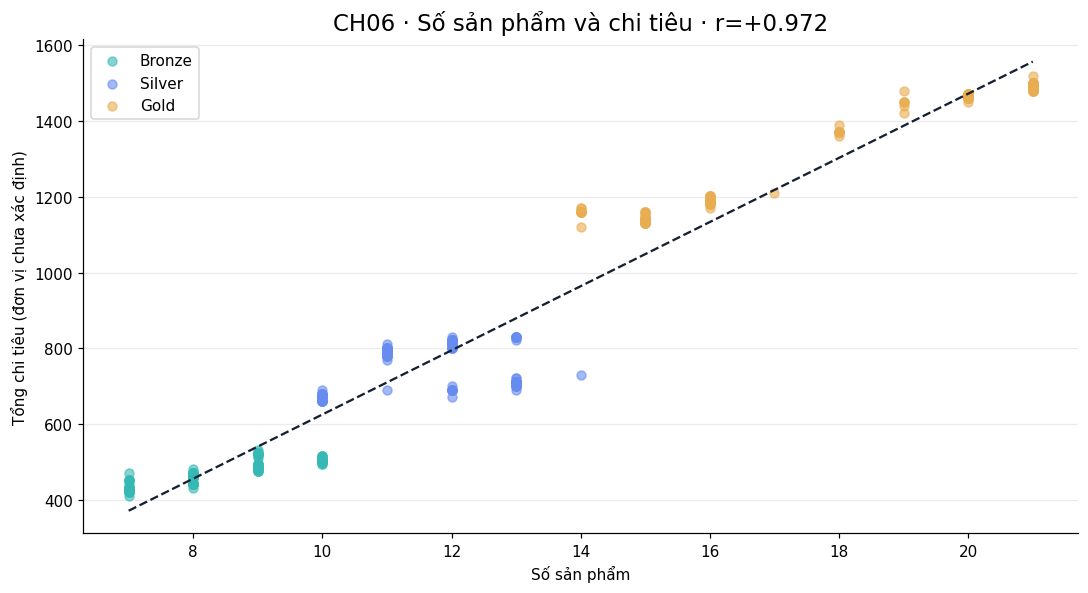

Pearson r=0.9724; N=350.


In [12]:
fig,ax=plt.subplots()
for m in MEMBERSHIPS:
 part=analysis_df[analysis_df["Membership Type"]==m]; ax.scatter(part["Items Purchased"],part["Total Spend"],color=COLORS[m],alpha=.6,s=34,label=m)
r_items=analysis_df["Items Purchased"].corr(analysis_df["Total Spend"]); coef=np.polyfit(analysis_df["Items Purchased"],analysis_df["Total Spend"],1); xs=np.array([analysis_df["Items Purchased"].min(),analysis_df["Items Purchased"].max()]); ax.plot(xs,coef[0]*xs+coef[1],"--",color="#162033")
ax.set(title=f"CH06 · Số sản phẩm và chi tiêu · r={r_items:+.3f}",xlabel="Số sản phẩm",ylabel=SPEND_AXIS_LABEL); ax.legend(); tidy(ax); plt.tight_layout(); save_chart(fig,"CH06_so_san_pham_va_chi_tieu.png"); plt.show(); print(f"Pearson r={r_items:.4f}; N={len(analysis_df)}.")

**Nhận xét:** Pearson r=+0,972, liên hệ dương rất mạnh trong mẫu; không chứng minh nguyên nhân.

### CH07 — Phân vùng khách hàng theo chi tiêu và lần mua gần nhất

**Kỹ thuật:** scatter phân vùng bằng trung vị `Total Spend` và `Days Since Last Purchase` của toàn bộ dữ liệu sạch. Ngưỡng được giữ cố định khi lọc để các phân khúc còn so sánh được.

**Ghi chú dữ liệu:** X=`Days Since Last Purchase`, Y=`Total Spend`; mỗi điểm là một `Customer ID`. Bốn màu lần lượt biểu diễn chi tiêu cao/thấp và mua gần đây/đã lâu. “Mua đã lâu” là dấu hiệu cần tái kích hoạt, không phải nhãn rời bỏ.


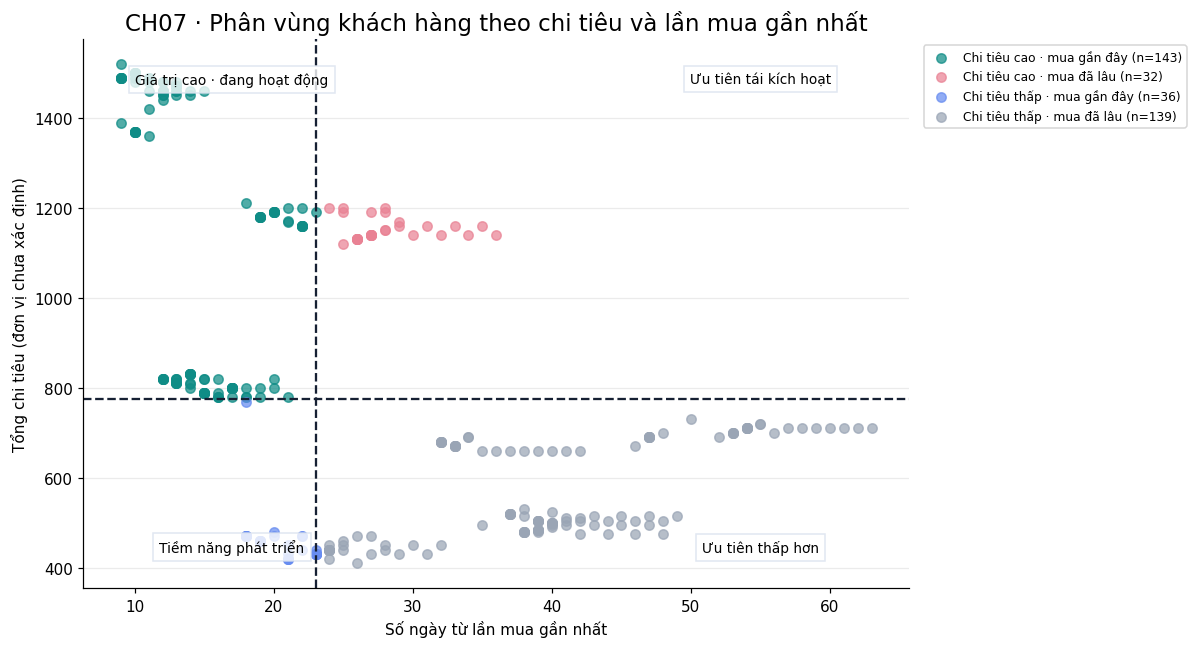

Ngưỡng cố định: chi tiêu=775.20; số ngày=23.0.
Customer Segment
Chi tiêu cao · mua gần đây     143
Chi tiêu cao · mua đã lâu       32
Chi tiêu thấp · mua gần đây     36
Chi tiêu thấp · mua đã lâu     139
Tổng=350; N=350.


In [13]:
# Nguồn: Total Spend, Days Since Last Purchase, Customer ID và Membership Type.
# Phạm vi: tập sau bộ lọc; ngưỡng lấy từ toàn bộ dữ liệu sạch để không đổi định nghĩa phân khúc.
spend_cut, days_cut = fixed_segmentation_thresholds(df)
segmented = assign_customer_segments(analysis_df, spend_cut=spend_cut, days_cut=days_cut)

fig, ax = plt.subplots(figsize=(11, 6))
for segment in SEGMENT_ORDER:
    part = segmented[segmented["Customer Segment"] == segment]
    ax.scatter(
        part["Days Since Last Purchase"], part["Total Spend"],
        color=SEGMENT_COLORS[segment], alpha=.72, s=38, label=f"{segment} (n={len(part)})"
    )
ax.axvline(days_cut, color="#162033", linestyle="--", linewidth=1.5)
ax.axhline(spend_cut, color="#162033", linestyle="--", linewidth=1.5)
ax.text(.18,.94,"Giá trị cao · đang hoạt động",transform=ax.transAxes,ha="center",va="top",fontsize=9,bbox={"facecolor":"white","alpha":.8,"edgecolor":"#D9E1EE"})
ax.text(.82,.94,"Ưu tiên tái kích hoạt",transform=ax.transAxes,ha="center",va="top",fontsize=9,bbox={"facecolor":"white","alpha":.8,"edgecolor":"#D9E1EE"})
ax.text(.18,.06,"Tiềm năng phát triển",transform=ax.transAxes,ha="center",va="bottom",fontsize=9,bbox={"facecolor":"white","alpha":.8,"edgecolor":"#D9E1EE"})
ax.text(.82,.06,"Ưu tiên thấp hơn",transform=ax.transAxes,ha="center",va="bottom",fontsize=9,bbox={"facecolor":"white","alpha":.8,"edgecolor":"#D9E1EE"})
ax.set(title="CH07 · Phân vùng khách hàng theo chi tiêu và lần mua gần nhất",xlabel="Số ngày từ lần mua gần nhất",ylabel=SPEND_AXIS_LABEL)
ax.legend(fontsize=8,loc="upper left",bbox_to_anchor=(1.01,1)); tidy(ax); plt.tight_layout()
save_chart(fig,"CH07_so_ngay_va_chi_tieu.png"); plt.show()
segment_counts=segmented["Customer Segment"].value_counts().reindex(SEGMENT_ORDER,fill_value=0)
print(f"Ngưỡng cố định: chi tiêu={spend_cut:.2f}; số ngày={days_cut:.1f}.")
print(segment_counts.to_string()); print(f"Tổng={segment_counts.sum()}; N={len(segmented)}.")


**Nhận xét:** với bộ lọc mặc định, nhóm “Chi tiêu cao · mua gần đây” có 143 khách; nhóm “Chi tiêu cao · mua đã lâu” có 32 khách và là nhóm ưu tiên tái kích hoạt. Đây là phân nhóm mô tả theo ngưỡng, không phải mô hình dự đoán churn.


## 9. Nhóm C — Hài lòng và giảm giá

### CH08 — Cột chồng 100% hài lòng theo hạng

**Kỹ thuật:** crosstab và chia theo tổng khách có nhãn hợp lệ trong chính từng hạng.

**Ghi chú dữ liệu:** dùng `Membership Type`, `Satisfaction Level`; chỉ CH08 loại thiếu. Tiêu chí: mỗi cột 100% và nhãn ghi n hợp lệ.

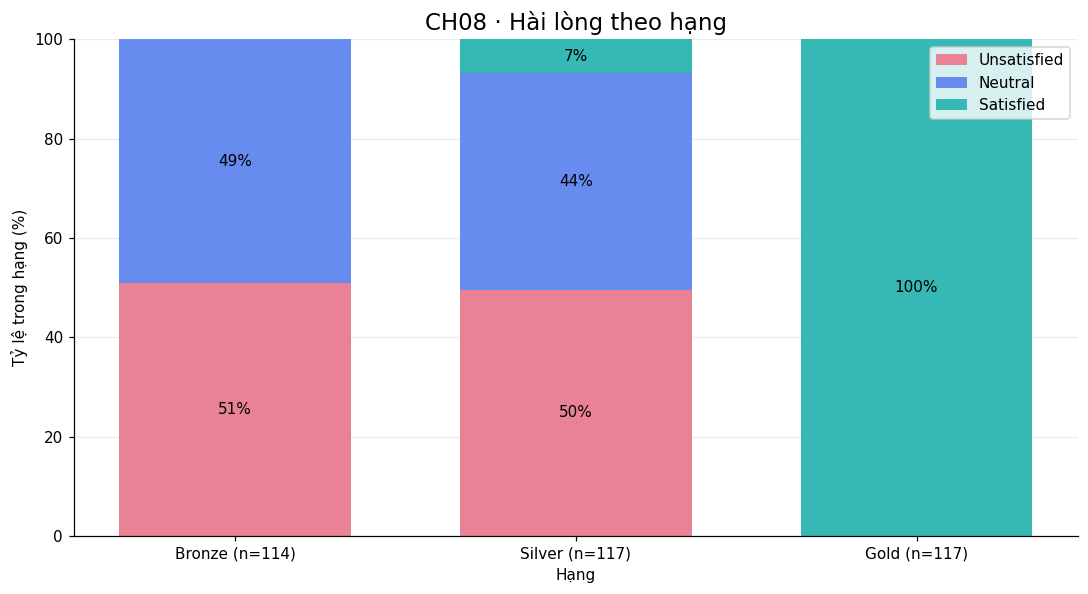

Satisfaction Level  Unsatisfied  Neutral  Satisfied
Membership Type                                    
Bronze                       58       56          0
Silver                       58       51          8
Gold                          0        0        117
Tổng tỷ lệ:
Membership Type
Bronze    100.0
Silver    100.0
Gold      100.0
Thiếu trong tập lọc: 2.


In [14]:
valid=analysis_df.dropna(subset=["Satisfaction Level"]); sat_counts=pd.crosstab(valid["Membership Type"],valid["Satisfaction Level"]).reindex(index=MEMBERSHIPS,columns=SATISFACTION_LEVELS,fill_value=0); sat_pct=sat_counts.div(sat_counts.sum(axis=1),axis=0).fillna(0)*100
fig,ax=plt.subplots(); bottom=np.zeros(len(MEMBERSHIPS)); labels=[f"{m} (n={sat_counts.loc[m].sum()})" for m in MEMBERSHIPS]
for level in SATISFACTION_LEVELS:
 values=sat_pct[level].to_numpy(); bars=ax.bar(labels,values,bottom=bottom,width=.68,color=SAT_COLORS[level],label=level)
 for bar,value,base in zip(bars,values,bottom):
  if value>=5: ax.text(bar.get_x()+bar.get_width()/2,base+value/2,f"{value:.0f}%",ha="center",va="center")
 bottom+=values
ax.set(title="CH08 · Hài lòng theo hạng",xlabel="Hạng",ylabel="Tỷ lệ trong hạng (%)",ylim=(0,100)); ax.legend(); tidy(ax); plt.tight_layout(); save_chart(fig,"CH08_hai_long_theo_hang.png"); plt.show()
print(sat_counts.to_string()); print("Tổng tỷ lệ:"); print(sat_pct.sum(axis=1).round(1).to_string()); print(f"Thiếu trong tập lọc: {analysis_df['Satisfaction Level'].isna().sum()}.")

**Nhận xét:** Gold 100% Satisfied; Bronze 50,9% Unsatisfied và 49,1% Neutral; Silver 6,8% Satisfied. Hai dòng thiếu chỉ loại khỏi CH08.

### CH09 — Chi tiêu và số sản phẩm theo tình trạng giảm giá

**Kỹ thuật:** hai boxplot song song Có/Không giảm giá; ô trái so sánh `Total Spend`, ô phải so sánh `Items Purchased`. Nhãn ghi số khách của từng nhóm.

**Ghi chú dữ liệu:** dùng `Discount Applied`, `Total Spend`, `Items Purchased`, `Customer ID`; giữ ngoại lệ để phản ánh phân phối thực. Tiêu chí là median, IQR và ngoại lệ; khác biệt quan sát được không chứng minh tác động nhân quả của giảm giá.


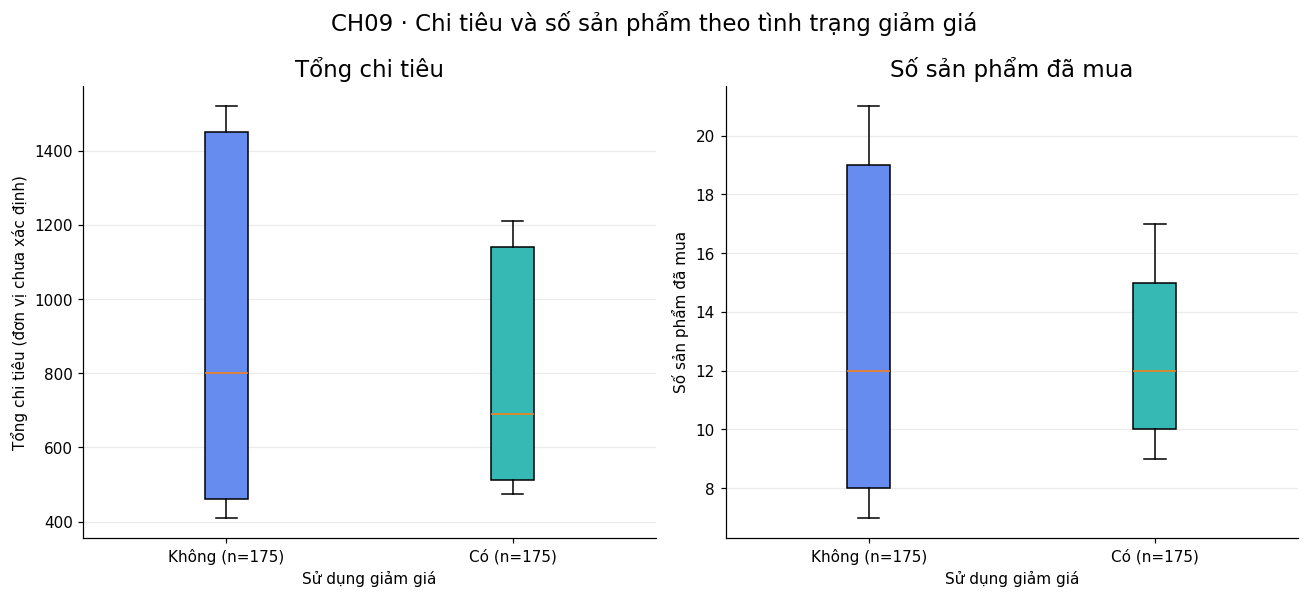

                 Total Spend                Items Purchased              
                       count    mean median           count   mean median
Discount Applied                                                         
False                    175  903.49  800.9             175  13.07   12.0
True                     175  787.27  690.6             175  12.13   12.0


In [15]:
# Nguồn: Discount Applied, Total Spend, Items Purchased và Customer ID.
# Điều kiện: so sánh hai nhóm Có/Không trên cùng tập dữ liệu sau bộ lọc.
discount_values=[False,True]; discount_names={False:"Không",True:"Có"}; discount_colors={False:"#678CF0",True:"#36B9B5"}
fig,axes=plt.subplots(1,2,figsize=(12,5.5))
for ax,measure,ylabel,title in [
    (axes[0],"Total Spend",SPEND_AXIS_LABEL,"Tổng chi tiêu"),
    (axes[1],"Items Purchased","Số sản phẩm đã mua","Số sản phẩm đã mua"),
]:
    groups=[analysis_df.loc[analysis_df["Discount Applied"]==value,measure].dropna() for value in discount_values]
    labels=[f"{discount_names[value]} (n={len(group)})" for value,group in zip(discount_values,groups)]
    bp=ax.boxplot(groups,patch_artist=True,tick_labels=labels)
    for box,value in zip(bp["boxes"],discount_values): box.set_facecolor(discount_colors[value])
    ax.set(title=title,xlabel="Sử dụng giảm giá",ylabel=ylabel); tidy(ax)
fig.suptitle("CH09 · Chi tiêu và số sản phẩm theo tình trạng giảm giá",fontsize=15); plt.tight_layout()
save_chart(fig,"CH09_chi_tieu_theo_giam_gia.png"); plt.show()
discount_summary=analysis_df.groupby("Discount Applied")[["Total Spend","Items Purchased"]].agg(["count","mean","median"])
print(discount_summary.round(2).to_string())


**Nhận xét:** median chi tiêu của nhóm Không giảm giá là 800,90 và nhóm Có giảm giá là 690,60; median số sản phẩm đều bằng 12. Khác biệt mô tả này chưa chứng minh giảm giá làm thay đổi hành vi mua.


## 10. Hồ sơ hành vi theo thành phố

### CH10 — Heatmap hồ sơ hành vi theo thành phố

**Kỹ thuật:** tổng hợp sáu chỉ tiêu theo `City`; màu được chuẩn hóa 0–100 riêng cho từng chỉ tiêu để so sánh tương đối giữa các thành phố, còn số ghi trong ô là giá trị thực.

**Ghi chú dữ liệu:** dùng `City`, `Customer ID`, `Total Spend`, `Items Purchased`, `Average Rating`, `Satisfaction Level`, `Discount Applied`, `Days Since Last Purchase`. Tỷ lệ hài lòng chỉ dùng khách có `Satisfaction Level` hợp lệ trong từng thành phố; số khách được ghi cạnh tên thành phố.


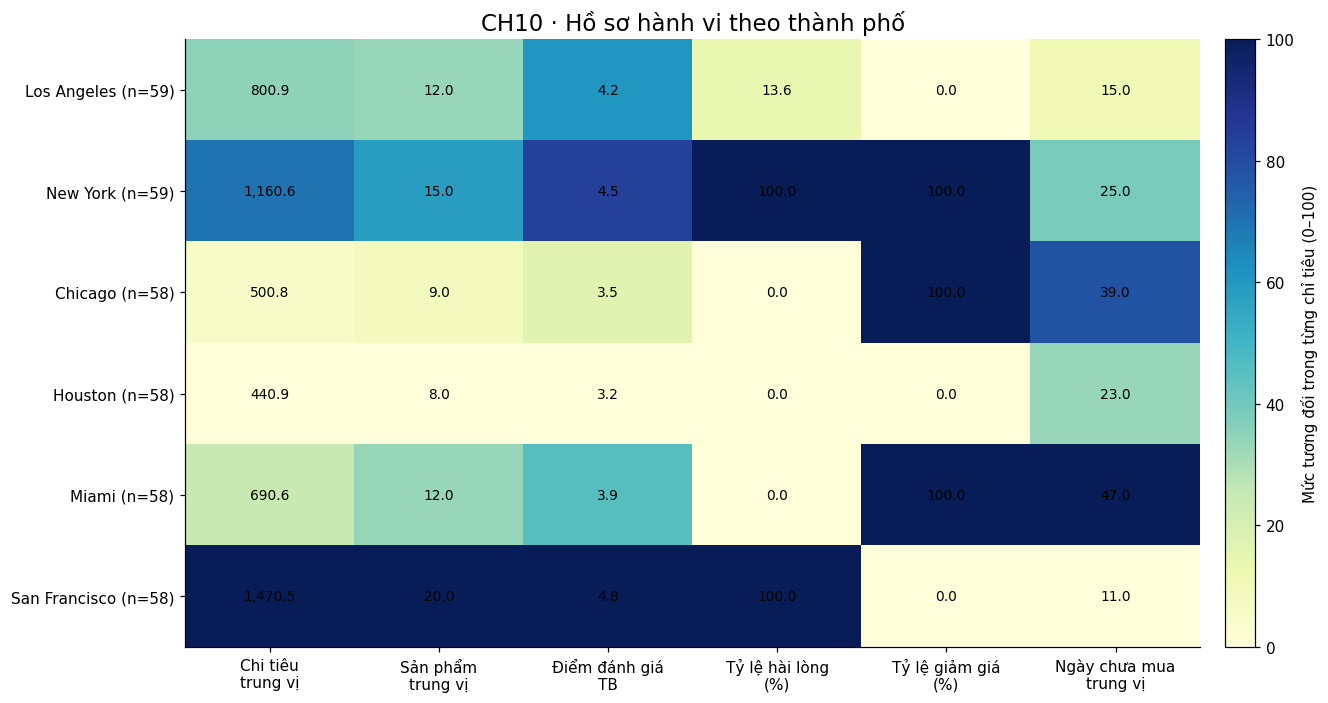

               Số khách  Chi tiêu trung vị  Sản phẩm trung vị  Điểm đánh giá TB  Tỷ lệ hài lòng (%)  Tỷ lệ giảm giá (%)  Ngày chưa mua trung vị
City                                                                                                                                           
Los Angeles          59             800.90               12.0              4.17               13.56                 0.0                    15.0
New York             59            1160.60               15.0              4.54              100.00               100.0                    25.0
Chicago              58             500.75                9.0              3.46                0.00               100.0                    39.0
Houston              58             440.90                8.0              3.19                0.00                 0.0                    23.0
Miami                58             690.60               12.0              3.93                0.00               100.0                 

In [16]:
# Nguồn và phạm vi: sáu chỉ tiêu hành vi được tổng hợp trên tập dữ liệu sau bộ lọc chung.
# Tiêu chí màu: 0 là thấp nhất và 100 là cao nhất trong từng cột; không so sánh màu giữa hai chỉ tiêu khác đơn vị.
city_profile=city_behavior_profile(analysis_df)
city_metrics=["Chi tiêu trung vị","Sản phẩm trung vị","Điểm đánh giá TB","Tỷ lệ hài lòng (%)","Tỷ lệ giảm giá (%)","Ngày chưa mua trung vị"]
actual=city_profile[city_metrics]
normalized=actual.copy().astype(float)
for column in city_metrics:
    low,high=actual[column].min(),actual[column].max()
    normalized[column]=50.0 if high==low else (actual[column]-low)/(high-low)*100

fig,ax=plt.subplots(figsize=(13,6.5))
image=ax.imshow(normalized.to_numpy(),aspect="auto",cmap="YlGnBu",vmin=0,vmax=100)
ax.set_xticks(range(len(city_metrics)),["Chi tiêu\ntrung vị","Sản phẩm\ntrung vị","Điểm đánh giá\nTB","Tỷ lệ hài lòng\n(%)","Tỷ lệ giảm giá\n(%)","Ngày chưa mua\ntrung vị"])
ax.set_yticks(range(len(city_profile)),[f"{city} (n={int(city_profile.loc[city,'Số khách'])})" for city in city_profile.index])
for row in range(len(actual)):
    for column in range(len(city_metrics)):
        value=actual.iloc[row,column]
        label_color="white" if normalized.iloc[row,column]>=60 else "black"
        ax.text(column,row,"—" if pd.isna(value) else f"{value:,.1f}",ha="center",va="center",fontsize=9,color=label_color)
ax.set_title("CH10 · Hồ sơ hành vi theo thành phố")
colorbar=fig.colorbar(image,ax=ax,pad=.02); colorbar.set_label("Mức tương đối trong từng chỉ tiêu (0–100)")
plt.tight_layout(); save_chart(fig,"CH10_ho_so_hanh_vi_theo_thanh_pho.png"); plt.show()
print(city_profile.round(2).to_string())


**Nhận xét:** với bộ lọc mặc định, San Francisco có median chi tiêu, median số sản phẩm và điểm đánh giá trung bình cao nhất, đồng thời median số ngày chưa mua thấp nhất. New York và San Francisco có tỷ lệ hài lòng 100% trong dữ liệu hợp lệ. Đây là khác biệt mô tả theo thành phố, không chứng minh vị trí địa lý gây ra hành vi.


## 11. Bảng phân nhóm bổ trợ cho CH07

**Kỹ thuật:** tổng hợp bốn vùng CH07 bằng median `Total Spend` và `Days Since Last Purchase` của toàn bộ dữ liệu sạch. Đây không phải RFM đầy đủ.


In [17]:
spend_cut,days_cut=fixed_segmentation_thresholds(df)
segmented=assign_customer_segments(analysis_df,spend_cut=spend_cut,days_cut=days_cut)
segments=segmented.groupby("Customer Segment").agg(so_khach=("Customer ID","nunique"),trung_vi_chi_tieu=("Total Spend","median"),trung_vi_so_ngay=("Days Since Last Purchase","median")).reindex(SEGMENT_ORDER)
segments["ty_trong_pct"]=segments["so_khach"]/len(segmented)*100
print(f"Ngưỡng cố định: chi tiêu={spend_cut:.2f} ({SPEND_UNIT}); ngày={days_cut:.1f}."); print(segments.round(2).to_string())


Ngưỡng cố định: chi tiêu=775.20 (đơn vị chưa xác định); ngày=23.0.
                             so_khach  trung_vi_chi_tieu  trung_vi_so_ngay  ty_trong_pct
Customer Segment                                                                        
Chi tiêu cao · mua gần đây        143            1180.80              14.0         40.86
Chi tiêu cao · mua đã lâu          32            1140.60              27.0          9.14
Chi tiêu thấp · mua gần đây        36             460.50              21.0         10.29
Chi tiêu thấp · mua đã lâu        139             515.75              39.0         39.71


**Diễn giải:** bốn nhóm dùng ngưỡng công khai; không gọi “trung thành” hay “nguy cơ rời bỏ” vì dữ liệu không đủ.

## 12. Kết luận và giới hạn

1. Dữ liệu sạch có 350 ID duy nhất; 2 dòng thiếu hài lòng được giữ cho các phân tích không dùng `Satisfaction Level`.
2. Tổng chi tiêu ghi nhận 295.883,60; median/khách 775,20; đơn vị tiền tệ chưa xác định.
3. CH07 xác định 32 khách “Chi tiêu cao · mua đã lâu” để ưu tiên tái kích hoạt; đây không phải dự đoán churn.
4. `Items Purchased`–`Total Spend` có Pearson r≈+0,972; mối liên hệ không chứng minh nhân quả.
5. Nhóm Không giảm giá có median chi tiêu cao hơn nhóm Có giảm giá, còn median số sản phẩm đều bằng 12; chưa thể kết luận tác động của khuyến mãi.
6. San Francisco nổi bật về chi tiêu, số sản phẩm, điểm đánh giá và mức độ mua gần đây trong so sánh thành phố.

**Giới hạn:** không có ngày giao dịch, chi tiết đơn, số lần đặt hàng, giá trị giảm giá, phân bổ khuyến mãi hoặc hành vi duyệt web; không tính doanh thu tháng, AOV, phễu, bỏ giỏ, churn hay RFM đầy đủ. Các so sánh theo giảm giá và thành phố chỉ là liên hệ mô tả.
